In [1]:
!pip install opencv-python scikit-image scikit-learn tensorflow matplotlib

You should consider upgrading via the 'C:\Users\Salsabila Alika\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [2]:
!pip install scikit-image

You should consider upgrading via the 'C:\Users\Salsabila Alika\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [3]:
!pip install pyradiomics SimpleITK

  Using cached pyradiomics-3.1.0.tar.gz (34.5 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
    Preparing wheel metadata: started
    Preparing wheel metadata: finished with status 'done'
  Using cached pyradiomics-3.0.1.tar.gz (34.5 MB)
  Running setup.py clean for pyradiomics
Failed to build pyradiomics
    Running setup.py install for pyradiomics: started
    Running setup.py install for pyradiomics: finished with status 'error'


  ERROR: Command errored out with exit status 1:
   command: 'C:\Users\Salsabila Alika\AppData\Local\Programs\Python\Python310\python.exe' -u -c 'import io, os, sys, setuptools, tokenize; sys.argv[0] = '"'"'C:\\Users\\Salsabila Alika\\AppData\\Local\\Temp\\pip-install-em8cffsd\\pyradiomics_a0339862cf58401eadcc9e517298ff13\\setup.py'"'"'; __file__='"'"'C:\\Users\\Salsabila Alika\\AppData\\Local\\Temp\\pip-install-em8cffsd\\pyradiomics_a0339862cf58401eadcc9e517298ff13\\setup.py'"'"';f = getattr(tokenize, '"'"'open'"'"', open)(__file__) if os.path.exists(__file__) else io.StringIO('"'"'from setuptools import setup; setup()'"'"');code = f.read().replace('"'"'\r\n'"'"', '"'"'\n'"'"');f.close();exec(compile(code, __file__, '"'"'exec'"'"'))' bdist_wheel -d 'C:\Users\Salsabila Alika\AppData\Local\Temp\pip-wheel-ptqoep4j'
       cwd: C:\Users\Salsabila Alika\AppData\Local\Temp\pip-install-em8cffsd\pyradiomics_a0339862cf58401eadcc9e517298ff13\
  Complete output (38 lines):
  C:\Users\Salsabila A

In [4]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops,  local_binary_pattern, hog
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
import seaborn as sns
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.applications.mobilenet import preprocess_input

1. DISTRIBUSI KUANTITATIF DATASET
Kelas Covid           -> Data Train: 111   | Data Test: 26    | Total: 137
Kelas Viral Pneumonia -> Data Train: 70    | Data Test: 20    | Total: 90
Kelas Normal          -> Data Train: 70    | Data Test: 20    | Total: 90
2. VISUALISASI KARAKTERISTIK VISUAL CITRA ASLI


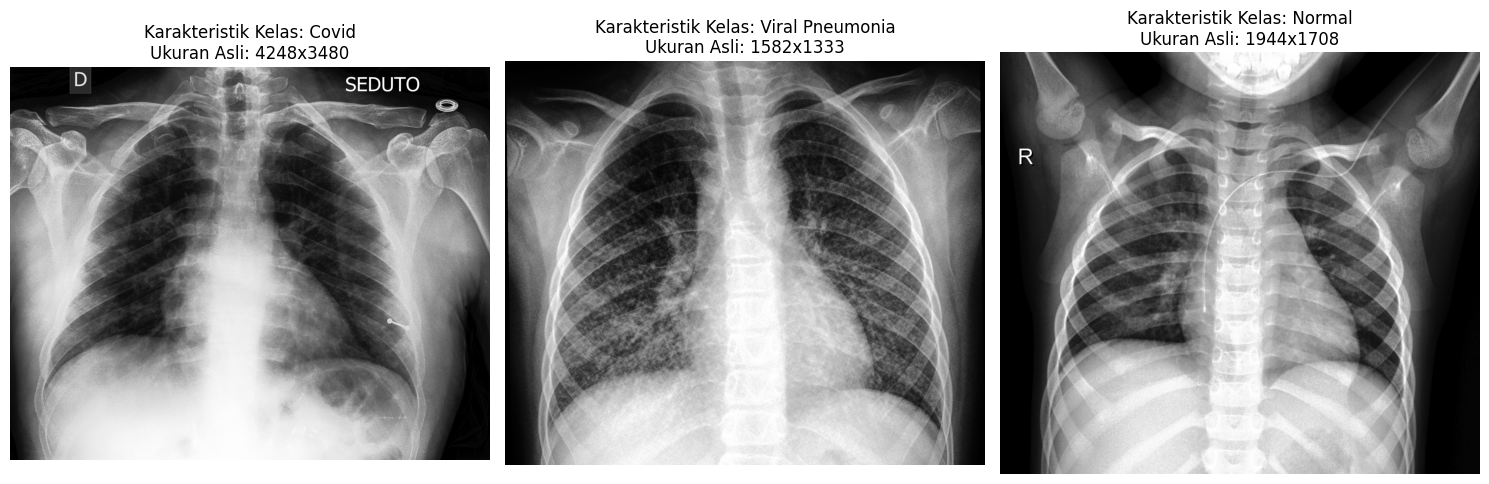

In [5]:
path_train = 'C:\\Users\\Salsabila Alika\\OneDrive\\Documents\\PCD\\proyek akhir\\Covid19-dataset\\train' 
path_test = 'C:\\Users\\Salsabila Alika\\OneDrive\\Documents\\PCD\\proyek akhir\\Covid19-dataset\\test'
categories = ['Covid', 'Viral Pneumonia', 'Normal']

print("1. DISTRIBUSI KUANTITATIF DATASET")
for category in categories:
    train_count = len(os.listdir(os.path.join(path_train, category)))
    test_count = len(os.listdir(os.path.join(path_test, category)))
    print(f"Kelas {category:<15} -> Data Train: {train_count:<5} | Data Test: {test_count:<5} | Total: {train_count + test_count}")
print("2. VISUALISASI KARAKTERISTIK VISUAL CITRA ASLI")
plt.figure(figsize=(15, 5))

for i, category in enumerate(categories):
    folder_path = os.path.join(path_train, category)
    sample_img_name = os.listdir(folder_path)[0] 
    sample_img_path = os.path.join(folder_path, sample_img_name)
    
    img = cv2.imread(sample_img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.subplot(1, 3, i+1)
    plt.imshow(img_rgb)
    plt.title(f"Karakteristik Kelas: {category}\nUkuran Asli: {img.shape[1]}x{img.shape[0]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:

def preprocess_image(image_path, target_size=(224, 224)):
    # 1. Baca citra sebagai grayscale untuk GLCM
    img_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
        return None, None 
    #2. Terapkan CLAHE untuk meningkatkan kontras
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_clahe = clahe.apply(img_gray)
    #3. Resize hasil CLAHE untuk GLCM
    img_glcm_ready = cv2.resize(img_clahe, target_size)
    
    # 1. Baca ulang sebagai citra berwarna asli (RGB 3-Channel)
    img_bgr = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if img_bgr is None:
        return None, None
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # 2. Resize ke ukuran standar input MobileNet (224x224)
    img_rgb_resized = cv2.resize(img_rgb, target_size)
    
    # 3. Normalisasi otomatis skala -1.0 s.d 1.0 sesuai standar asli MobileNet
    img_mobile_ready = preprocess_input(img_rgb_resized.astype('float32'))
    
    return img_glcm_ready, img_mobile_ready

def load_dataset(base_dir, target_size=(224, 224)):
    categories = ['Covid', 'Viral Pneumonia', 'Normal'] 
    X_glcm, X_mobile, y = [], [], []
    
    for idx, category in enumerate(categories):
        folder_path = os.path.join(base_dir, category)
        if not os.path.exists(folder_path):
            print(f"Peringatan: Folder {folder_path} tidak ditemukan")
            continue
        for img_name in os.listdir(folder_path):
            img_path = os.path.join(folder_path, img_name)
            
            img_glcm, img_mobile = preprocess_image(img_path, target_size)
            
            if img_glcm is not None and img_mobile is not None:
                X_glcm.append(img_glcm)      
                X_mobile.append(img_mobile)  
                y.append(idx)
                
    return np.array(X_glcm), np.array(X_mobile), np.array(y)

# EXECUTION TAHAP AWAL
path_train = 'C:\\Users\\Salsabila Alika\\OneDrive\\Documents\\PCD\\proyek akhir\\Covid19-dataset\\train' 
path_test = 'C:\\Users\\Salsabila Alika\\OneDrive\\Documents\\PCD\\proyek akhir\\Covid19-dataset\\test'

X_train_glcm, X_train_mobile, y_train = load_dataset(path_train)
X_test_glcm, X_test_mobile, y_test = load_dataset(path_test)

print(f"\nProses preprocessing selesai.")
print(f"Data Train GLCM    : {X_train_glcm.shape} | Nilai Rentang: {X_train_glcm.min()} s.d {X_train_glcm.max()}")
print(f"Data Train Mobile  : {X_train_mobile.shape} | Nilai Rentang: {X_train_mobile.min()} s.d {X_train_mobile.max()}")
print(f"Data Test Citra    : Total {len(y_test)} citra uji.")


Proses preprocessing selesai.
Data Train GLCM    : (251, 224, 224) | Nilai Rentang: 0 s.d 255
Data Train Mobile  : (251, 224, 224, 3) | Nilai Rentang: -1.0 s.d 1.0
Data Test Citra    : Total 66 citra uji.


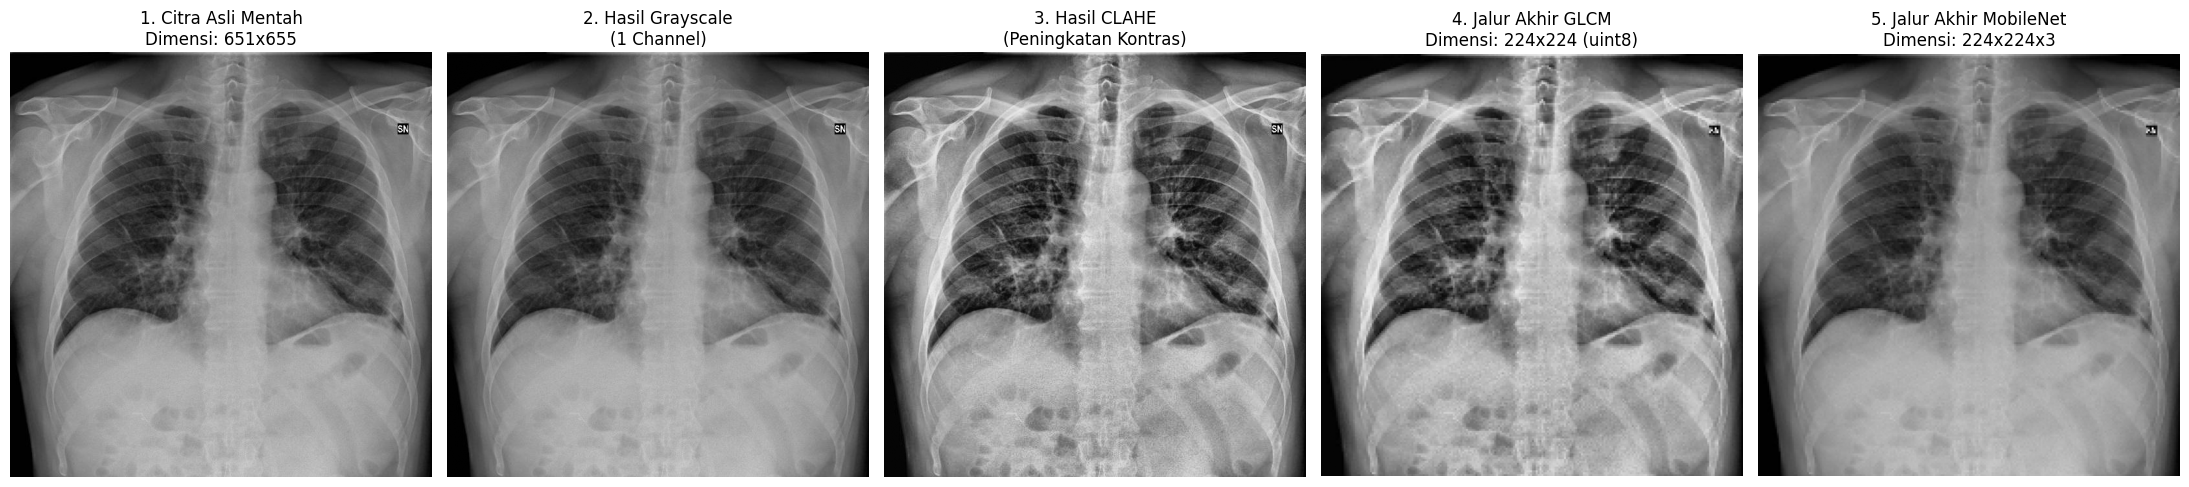

In [7]:
sample_image_path = "C:\\Users\\Salsabila Alika\\OneDrive\\Documents\\PCD\\proyek akhir\\Covid19-dataset\\test\\Covid\\COVID-00022.jpg" 

img_original_bgr = cv2.imread(sample_image_path)

if img_original_bgr is not None:
    img_glcm_res, img_mobile_res = preprocess_image(sample_image_path, target_size=(224, 224))
    
    img_gray = cv2.cvtColor(img_original_bgr, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_clahe = clahe.apply(img_gray)
    img_mobile_display = (img_mobile_res - img_mobile_res.min()) / (img_mobile_res.max() - img_mobile_res.min())

    plt.figure(figsize=(22, 5))
    plt.subplot(1, 5, 1)
    plt.imshow(cv2.cvtColor(img_original_bgr, cv2.COLOR_BGR2RGB))
    plt.title(f"1. Citra Asli Mentah\nDimensi: {img_original_bgr.shape[1]}x{img_original_bgr.shape[0]}")
    plt.axis('off')
    
    plt.subplot(1, 5, 2)
    plt.imshow(img_gray, cmap='gray')
    plt.title("2. Hasil Grayscale\n(1 Channel)")
    plt.axis('off')
    
    plt.subplot(1, 5, 3)
    plt.imshow(img_clahe, cmap='gray')
    plt.title("3. Hasil CLAHE\n(Peningkatan Kontras)")
    plt.axis('off')
    
    plt.subplot(1, 5, 4)
    plt.imshow(img_glcm_res, cmap='gray')
    plt.title(f"4. Jalur Akhir GLCM\nDimensi: {img_glcm_res.shape[1]}x{img_glcm_res.shape[0]} (uint8)")
    plt.axis('off')
    
    plt.subplot(1, 5, 5)
    plt.imshow(img_mobile_display)
    plt.title(f"5. Jalur Akhir MobileNet\nDimensi: {img_mobile_res.shape[1]}x{img_mobile_res.shape[0]}x{img_mobile_res.shape[2]}")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

else:
    print("Error: File gambar tidak ditemukan!")

In [8]:
def extract_glcm_features(images):
    glcm_features = []
    for img in images:
        glcm = graycomatrix(img, distances=[2], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256, symmetric=True, normed=True)
        
        contrast = graycoprops(glcm, 'contrast').ravel()
        correlation = graycoprops(glcm, 'correlation').ravel()
        energy = graycoprops(glcm, 'energy').ravel()
        homogeneity = graycoprops(glcm, 'homogeneity').ravel()
        dissimilarity = graycoprops(glcm, 'dissimilarity').ravel()
        asm = graycoprops(glcm, 'ASM').ravel()

        feature_vector = np.hstack([contrast, correlation, energy, homogeneity, dissimilarity, asm])
        glcm_features.append(feature_vector)
        
    return np.array(glcm_features)

X_train_features_glcm = extract_glcm_features(X_train_glcm)
X_test_features_glcm = extract_glcm_features(X_test_glcm)

In [9]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train_features_glcm)

X_test_scaled = scaler.transform(X_test_features_glcm)

model_svm = SVC(kernel='rbf', C=50, gamma='scale', probability=True)
model_svm.fit(X_train_scaled, y_train)

y_pred_svm = model_svm.predict(X_test_scaled) 
print("Model Klasik GLCM-SVM selesai dilatih dan diuji dengan MinMaxScaler")

Model Klasik GLCM-SVM selesai dilatih dan diuji dengan MinMaxScaler


In [25]:
def build_mobilenet_model(num_classes=3):
    base_model = MobileNet(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    
    base_model.trainable = False 

    x = base_model.output
    x = GlobalAveragePooling2D()(x) 
    x = Dense(128, activation='relu')(x)
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    
    return model

model_mobile = build_mobilenet_model(num_classes=3)

history = model_mobile.fit(X_train_mobile, y_train, validation_data=(X_test_mobile, y_test), epochs=10, batch_size=16)

y_pred_mobile_prob = model_mobile.predict(X_test_mobile)
y_pred_mobile = np.argmax(y_pred_mobile_prob, axis=1)
print("Model Modern MobileNet selesai dilatih dan diuji")

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 235ms/step - accuracy: 0.7092 - loss: 0.7813 - val_accuracy: 0.7424 - val_loss: 0.4445
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 160ms/step - accuracy: 0.9442 - loss: 0.2120 - val_accuracy: 0.8939 - val_loss: 0.2700
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 162ms/step - accuracy: 0.9721 - loss: 0.1156 - val_accuracy: 0.9091 - val_loss: 0.2063
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 163ms/step - accuracy: 0.9841 - loss: 0.0863 - val_accuracy: 0.9242 - val_loss: 0.1663
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 163ms/step - accuracy: 0.9801 - loss: 0.0602 - val_accuracy: 0.9697 - val_loss: 0.1600
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 164ms/step - accuracy: 0.9880 - loss: 0.0501 - val_accuracy: 0.9848 - val_loss: 0.1117
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 162ms/step - accuracy: 0.9960 - loss: 0.0345 - val_accuracy: 0.9394 - val_loss: 0.1520
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 173ms/step - accuracy: 1.0000 - loss: 0.0255 - val_accuracy: 0.

In [26]:
def evaluate_and_compare(y_true, y_pred_classic, y_pred_modern):
    target_names = ['COVID-19', 'Viral Pneumonia', 'Normal']
    
    print(" EVALUASI METODE KLASIK (GLCM-SVM) ")
    print(classification_report(y_true, y_pred_classic, target_names=target_names))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred_classic))
    
    print(" EVALUASI METODE MODERN (MOBILENET)")
    print(classification_report(y_true, y_pred_modern, target_names=target_names))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred_modern))

evaluate_and_compare(y_test, y_pred_svm, y_pred_mobile)

 EVALUASI METODE KLASIK (GLCM-SVM) 
                 precision    recall  f1-score   support

       COVID-19       0.96      0.96      0.96        26
Viral Pneumonia       0.75      0.90      0.82        20
         Normal       0.88      0.70      0.78        20

       accuracy                           0.86        66
      macro avg       0.86      0.85      0.85        66
   weighted avg       0.87      0.86      0.86        66

Confusion Matrix:
[[25  0  1]
 [ 1 18  1]
 [ 0  6 14]]
 EVALUASI METODE MODERN (MOBILENET)
                 precision    recall  f1-score   support

       COVID-19       1.00      1.00      1.00        26
Viral Pneumonia       0.91      1.00      0.95        20
         Normal       1.00      0.90      0.95        20

       accuracy                           0.97        66
      macro avg       0.97      0.97      0.97        66
   weighted avg       0.97      0.97      0.97        66

Confusion Matrix:
[[26  0  0]
 [ 0 20  0]
 [ 0  2 18]]


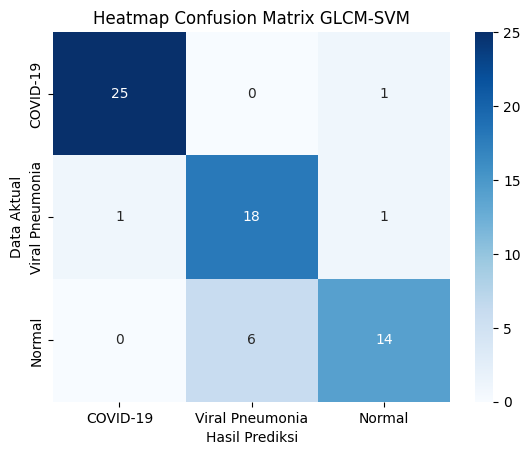

In [12]:
cm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['COVID-19', 'Viral Pneumonia', 'Normal'],
            yticklabels=['COVID-19', 'Viral Pneumonia', 'Normal'])
plt.ylabel('Data Aktual')
plt.xlabel('Hasil Prediksi')
plt.title('Heatmap Confusion Matrix GLCM-SVM')
plt.show()

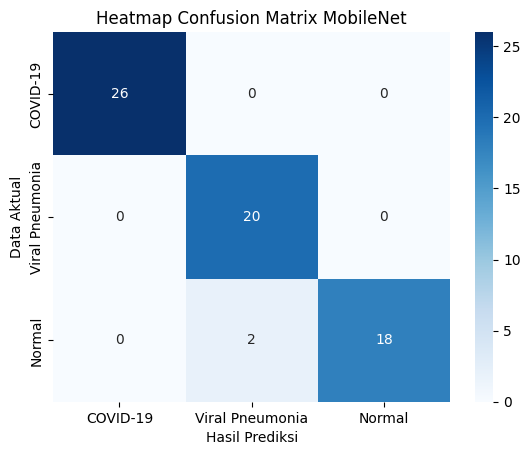

In [27]:
cm = confusion_matrix(y_test, y_pred_mobile)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['COVID-19', 'Viral Pneumonia', 'Normal'],
            yticklabels=['COVID-19', 'Viral Pneumonia', 'Normal'])
plt.ylabel('Data Aktual')
plt.xlabel('Hasil Prediksi')
plt.title('Heatmap Confusion Matrix MobileNet')
plt.show()

Analisis lanjutan

In [14]:
def extract_lbp_features(images):
    lbp_features = []

    radius = 1
    n_points = 8 * radius

    for img in images:
        lbp = local_binary_pattern(
            img,
            n_points,
            radius,
            method='uniform'
        )

        hist, _ = np.histogram(
            lbp.ravel(),
            bins=np.arange(0, n_points + 3),
            range=(0, n_points + 2)
        )

        hist = hist.astype("float")
        hist /= (hist.sum() + 1e-6)

        lbp_features.append(hist)

    return np.array(lbp_features)

X_train_features_lbp = extract_lbp_features(X_train_glcm)
X_test_features_lbp = extract_lbp_features(X_test_glcm)

X_train_combined = np.hstack((X_train_features_glcm, X_train_features_lbp))
X_test_combined = np.hstack((X_test_features_glcm, X_test_features_lbp))

scaler_combined = MinMaxScaler()

X_train_combined_scaled = scaler_combined.fit_transform(X_train_combined)

X_test_combined_scaled = scaler_combined.transform(X_test_combined)

model_svm_lbp = SVC(
    kernel='rbf',
    C=50,
    gamma='scale',
    probability=True
)

model_svm_lbp.fit(X_train_combined_scaled, y_train)

y_pred_svm_lbp = model_svm_lbp.predict(X_test_combined_scaled)

print("Model GLCM + LBP + SVM selesai dilatih dan diuji dengan MinMaxScaler")

Model GLCM + LBP + SVM selesai dilatih dan diuji dengan MinMaxScaler


In [15]:
print(" EVALUASI METODE KLASIK (GLCM + LBP + SVM)")
print(classification_report(y_test, y_pred_svm_lbp, target_names=['COVID-19', 'Viral Pneumonia', 'Normal']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm_lbp))

 EVALUASI METODE KLASIK (GLCM + LBP + SVM)
                 precision    recall  f1-score   support

       COVID-19       0.90      1.00      0.95        26
Viral Pneumonia       0.76      0.65      0.70        20
         Normal       0.80      0.80      0.80        20

       accuracy                           0.83        66
      macro avg       0.82      0.82      0.82        66
   weighted avg       0.83      0.83      0.83        66

Confusion Matrix:
[[26  0  0]
 [ 3 13  4]
 [ 0  4 16]]


In [16]:
def extract_hog_features(images):
    hog_features = []

    for img in images:

        features = hog(
    img,
    orientations=12,
    pixels_per_cell=(50,50),
    cells_per_block=(2, 2),
    block_norm='L2-Hys',
    visualize=False,
    feature_vector=True
)

        hog_features.append(features)

    return np.array(hog_features)

X_train_features_hog = extract_hog_features(X_train_glcm)
X_test_features_hog = extract_hog_features(X_test_glcm)

X_train_combined_hog = np.hstack((X_train_features_glcm, X_train_features_hog))
X_test_combined_hog = np.hstack((X_test_features_glcm, X_test_features_hog))

scaler_hog_combined = MinMaxScaler()

X_train_combined_hog_scaled = scaler_hog_combined.fit_transform(X_train_combined_hog)

X_test_combined_hog_scaled = scaler_hog_combined.transform(X_test_combined_hog)

model_svm_hog = SVC(
    kernel='rbf',
    C=50,
    gamma='scale',
    probability=True
)
model_svm_hog.fit(X_train_combined_hog_scaled, y_train)

y_pred_svm_hog = model_svm_hog.predict(X_test_combined_hog_scaled)

print("Model GLCM + HOG + SVM selesai dilatih dan diuji dengan Scaling")

Model GLCM + HOG + SVM selesai dilatih dan diuji dengan Scaling


In [17]:
print(" EVALUASI METODE KLASIK (GLCM + HOG + SVM)")
print(classification_report(y_test, y_pred_svm_hog, target_names=['COVID-19', 'Viral Pneumonia', 'Normal']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm_hog))

 EVALUASI METODE KLASIK (GLCM + HOG + SVM)
                 precision    recall  f1-score   support

       COVID-19       1.00      1.00      1.00        26
Viral Pneumonia       0.83      1.00      0.91        20
         Normal       1.00      0.80      0.89        20

       accuracy                           0.94        66
      macro avg       0.94      0.93      0.93        66
   weighted avg       0.95      0.94      0.94        66

Confusion Matrix:
[[26  0  0]
 [ 0 20  0]
 [ 0  4 16]]


In [18]:
def extract_glrlm_features(images):

    glrlm_features = []

    for img in images:

        img = img.astype(np.uint8)

        runs = []

        for row in img:

            current_pixel = row[0]
            run_length = 1

            for pixel in row[1:]:

                if pixel == current_pixel:
                    run_length += 1
                else:
                    runs.append(run_length)
                    current_pixel = pixel
                    run_length = 1

            runs.append(run_length)

        short_run = np.mean(runs)
        long_run = np.max(runs)
        run_std = np.std(runs)
        run_sum = np.sum(runs)

        feature_vector = [
            short_run,
            long_run,
            run_std,
            run_sum
        ]

        glrlm_features.append(feature_vector)

    return np.array(glrlm_features)

X_train_features_glrlm = extract_glrlm_features(X_train_glcm)
X_test_features_glrlm = extract_glrlm_features(X_test_glcm)

X_train_combined_glrlm = np.hstack((
    X_train_features_glcm,
    X_train_features_glrlm
))

X_test_combined_glrlm = np.hstack((
    X_test_features_glcm,
    X_test_features_glrlm
))

scaler_glrlm_comb = MinMaxScaler()

X_train_combined_glrlm_scaled = scaler_glrlm_comb.fit_transform(X_train_combined_glrlm)

X_test_combined_glrlm_scaled = scaler_glrlm_comb.transform(X_test_combined_glrlm)

model_svm_glrlm = SVC(
    kernel='rbf',
    C=50,
    gamma='scale',
    probability=True
)

model_svm_glrlm.fit(
    X_train_combined_glrlm_scaled,
    y_train
)

y_pred_svm_glrlm = model_svm_glrlm.predict(
    X_test_combined_glrlm_scaled
)

print("Model GLCM + GLRLM + SVM selesai dilatih dan diuji dengan MinMaxScaler")

Model GLCM + GLRLM + SVM selesai dilatih dan diuji dengan MinMaxScaler


In [19]:
print(" EVALUASI METODE KLASIK (GLCM + GLRLM + SVM)")
print(classification_report(y_test, y_pred_svm_glrlm, target_names=['COVID-19', 'Viral Pneumonia', 'Normal']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm_glrlm))

 EVALUASI METODE KLASIK (GLCM + GLRLM + SVM)
                 precision    recall  f1-score   support

       COVID-19       1.00      1.00      1.00        26
Viral Pneumonia       0.73      0.95      0.83        20
         Normal       0.93      0.65      0.76        20

       accuracy                           0.88        66
      macro avg       0.89      0.87      0.86        66
   weighted avg       0.90      0.88      0.88        66

Confusion Matrix:
[[26  0  0]
 [ 0 19  1]
 [ 0  7 13]]
